# Ruteo urbano multiobjetivo en Medellín
### Rutas óptimas combinando **seguridad, cámaras, distancia y velocidad**

---

**Objetivo.** Construir un grafo vial de Medellín y encontrar la mejor ruta entre dos puntos usando una
función de costo que no solo mira el tiempo de viaje, sino también:

| Parámetro | Fuente de datos | Efecto sobre el costo |
|---|---|---|
| **Seguridad del barrio** | `hurto_a_persona`, `hurto_de_moto`, `hurto_de_carro`, `hurto_por_pirateria_terrestre` + `Criminalidad por Comuna` | ⬆ penaliza |
| **Cámaras (fotodetección)** | `202608091356-ansv-fotodeteccion` (ANSV) | ⬇ bonifica (disuasión) |
| **Distancia** | Geometría del grafo OSM (`length`) | ⬆ penaliza |
| **Velocidad** | `velocidad_e_intensidad_vehicular_en_medellin` + `maxspeed` de OSM | ⬇ mayor velocidad, menor costo |

La estructura sigue el notebook de referencia `IA_EIA_LatLong_InformacionMapa.ipynb`
(OSMnx → grafo → `networkx.shortest_path` → visualización), pero reemplazando el peso simple
`travel_time` por un **costo compuesto normalizado y parametrizable**.

## Índice

0. Instalación e imports
1. Carga y limpieza de las cuatro fuentes de datos
2. Exploración rápida (EDA)
3. Construcción del grafo vial con OSMnx
4. Enriquecimiento del grafo (riesgo, cámaras, velocidad observada, congestión)
5. La heurística: función de costo multiobjetivo
6. Algoritmos de ruteo: Dijkstra y A\*
7. Comparación de perfiles de ruta
8. Mapa interactivo con Folium
9. Análisis de sensibilidad / frontera de Pareto
10. Conclusiones

## 0. Instalación e imports

Ejecutar una sola vez. En Google Colab, **reiniciar el entorno** después de instalar `osmnx`.

In [1]:
# ======================================================================
# CELDA DE INSTALACIÓN — ejecutar PRIMERO, antes que cualquier otra cosa
# ======================================================================
# Detecta lo que falta, instala solo eso, y verifica que todo quede bien.
# Se puede volver a ejecutar sin problema: si ya está todo, no hace nada.
#
# Tres trampas que esta celda te evita:
#   1. osmnx 2.x NO instala matplotlib solo: es dependencia opcional.
#   2. osmnx decide si puede graficar EN EL MOMENTO en que se importa. Si lo
#      importas antes de que matplotlib exista, queda desactivado toda la
#      sesión y `plot_graph_routes` falla con "matplotlib must be installed
#      as an optional dependency", aunque después lo instales. La celda lo
#      detecta y te avisa de que hay que reiniciar el kernel.
#   3. Usa `sys.executable -m pip` en vez de `!pip`. Con un .venv, `!pip`
#      puede apuntar a otro Python y dejarte instalando en el sitio erróneo.

import importlib, subprocess, sys

# nombre en pip -> nombre con el que se importa
REQUISITOS = {
    # núcleo del análisis
    "numpy":        "numpy",
    "pandas":       "pandas",
    "networkx":     "networkx",
    "scipy":        "scipy",         # lo usa ox.distance.nearest_nodes por dentro
    "scikit-learn": "sklearn",       # BallTree (búsquedas haversine)
    # geo
    "osmnx":        "osmnx",
    "geopandas":    "geopandas",     # lo devuelve ox.graph_to_gdfs
    "shapely":      "shapely",       # geometrías de las aristas
    "pyproj":       "pyproj",        # reproyección EPSG:3116 -> EPSG:4326
    "geopy":        "geopy",         # geocodificación con Nominatim
    "requests":     "requests",      # descarga de OSM
    # visualización
    "matplotlib":   "matplotlib",    # OJO: opcional para osmnx, pero aquí es obligatoria
    "folium":       "folium",        # mapas interactivos
}

faltan = [pip for pip, imp in REQUISITOS.items() if importlib.util.find_spec(imp) is None]

if faltan:
    print("Instalando:", ", ".join(faltan))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltan])
    importlib.invalidate_caches()
else:
    print("Todas las dependencias ya estaban instaladas.")

# ---------------------- verificación ----------------------
print("\n%-16s %s" % ("paquete", "versión"))
print("-" * 34)
problemas = []
for pip_name, mod_name in REQUISITOS.items():
    try:
        m = importlib.import_module(mod_name)
        print("%-16s %s" % (pip_name, getattr(m, "__version__", "ok")))
    except Exception as e:
        print("%-16s FALTA (%s)" % (pip_name, type(e).__name__))
        problemas.append(pip_name)

# ---------------------- la trampa de osmnx + matplotlib ----------------------
reiniciar = False
if "osmnx" in sys.modules:
    try:
        from osmnx import plot as _oxplot
        if not getattr(_oxplot, "mpl_available", True):
            reiniciar = True
    except Exception:
        pass

print()
if problemas:
    print("FALTAN:", ", ".join(problemas), "-> revisa el log de pip de arriba.")
elif reiniciar:
    print("*** REINICIA EL KERNEL Y VUELVE A EJECUTAR DESDE AQUÍ. ***")
    print("osmnx se importó antes de que matplotlib estuviera disponible, así que")
    print("tiene el dibujo desactivado. Solo se arregla reiniciando.")
else:
    print("Todo listo. Puedes seguir con la celda de imports.")

Todas las dependencias ya estaban instaladas.

paquete          versión
----------------------------------
numpy            2.5.2
pandas           3.0.5
networkx         3.6.1
scipy            1.18.0
scikit-learn     1.9.0
osmnx            2.1.1
geopandas        1.1.4
shapely          2.1.2
pyproj           3.7.2
geopy            2.5.0
requests         2.34.2
matplotlib       3.11.1
folium           0.20.0

Todo listo. Puedes seguir con la celda de imports.


In [2]:
import os, re, json, warnings, unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import osmnx as ox
import folium
from folium.plugins import HeatMap, MarkerCluster, Fullscreen
import matplotlib.pyplot as plt
from sklearn.neighbors import BallTree
from pyproj import Transformer

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
plt.rcParams["figure.figsize"] = (11, 6)

print("osmnx", ox.__version__, "| networkx", nx.__version__, "| folium", folium.__version__)

osmnx 2.1.1 | networkx 3.6.1 | folium 0.20.0


In [3]:
# ----------------------------------------------------------------------
# CONFIGURACIÓN GLOBAL
# ----------------------------------------------------------------------
DATA_DIR  = Path("datos")     # <- carpeta con los CSV
CACHE_DIR = Path("cache"); CACHE_DIR.mkdir(exist_ok=True)
SALIDA    = Path("salidas");  SALIDA.mkdir(exist_ok=True)

ARCHIVOS = {
    "persona":    "hurto_a_persona.csv",
    "moto":       "hurto_de_moto.csv",
    "carro":      "hurto_de_carro.csv",
    "pirateria":  "hurto_por_pirateria_terrestre.csv",
    "camaras":    "202608091356-ansv-fotodeteccion.csv",
    "velocidad":  "velocidad_e_intensidad_vehicular_en_medellin.csv",
    "comunas":    "Criminalidad por Comuna_data.csv",
}

# Caja geográfica del Valle de Aburrá (para descartar coordenadas erróneas)
BBOX = dict(lat_min=6.13, lat_max=6.40, lon_min=-75.72, lon_max=-75.47)

ANIO_MIN = 2019               # solo hechos recientes
R_TIERRA = 6371008.8          # radio medio terrestre (m) para haversine

# Radios de influencia (metros)
RADIO_CRIMEN  = 300           # cuánto "irradia" un hurto sobre las vías cercanas
RADIO_CAMARA  = 400           # alcance disuasorio de una cámara
RADIO_SENSOR  = 700           # distancia máx. para asignar un sensor de velocidad a una vía

for k, v in ARCHIVOS.items():
    p = DATA_DIR / v
    print(f"{'OK ' if p.exists() else 'FALTA'} {k:10s} -> {v}")

OK  persona    -> hurto_a_persona.csv
OK  moto       -> hurto_de_moto.csv
OK  carro      -> hurto_de_carro.csv
OK  pirateria  -> hurto_por_pirateria_terrestre.csv
OK  camaras    -> 202608091356-ansv-fotodeteccion.csv
OK  velocidad  -> velocidad_e_intensidad_vehicular_en_medellin.csv
OK  comunas    -> Criminalidad por Comuna_data.csv


## 1. Carga y limpieza de datos

Cuatro bloques independientes. Cada uno termina en un `DataFrame` limpio con
`lat` / `lon` en **EPSG:4326**, listo para indexar espacialmente.

### 1.1 Hurtos (seguridad)

Los cuatro archivos de hurto comparten el mismo esquema de la Alcaldía de Medellín.
Se concatenan y se asigna un **peso por tipo de delito**, porque no todos afectan igual
a alguien que se está desplazando:

* `hurto_a_persona` → riesgo directo al viajero → peso **1.0**
* `hurto_de_moto` / `hurto_de_carro` → riesgo al vehículo estacionado o en semáforo → peso **0.8**
* `hurto_por_pirateria_terrestre` → asalto a vehículo en marcha, el más grave para una ruta → peso **1.2**

In [4]:
PESO_DELITO = {"persona": 1.0, "moto": 0.8, "carro": 0.8, "pirateria": 1.2}

COLS_HURTO = ["fecha_hecho", "cantidad", "latitud", "longitud",
              "nombre_barrio", "codigo_comuna", "lugar", "modalidad", "conducta"]

def cargar_hurtos():
    partes = []
    for tipo, w in PESO_DELITO.items():
        ruta = DATA_DIR / ARCHIVOS[tipo]
        d = pd.read_csv(ruta, usecols=COLS_HURTO, low_memory=False)
        d["tipo"] = tipo
        d["peso_tipo"] = w
        partes.append(d)
        print(f"  {tipo:10s} {len(d):>7,} registros")
    df = pd.concat(partes, ignore_index=True)

    df["anio"] = pd.to_numeric(df["fecha_hecho"].astype(str).str[:4], errors="coerce")
    df["hora_hecho"] = pd.to_numeric(df["fecha_hecho"].astype(str).str[11:13], errors="coerce")
    df["latitud"]  = pd.to_numeric(df["latitud"],  errors="coerce")
    df["longitud"] = pd.to_numeric(df["longitud"], errors="coerce")

    n0 = len(df)
    df = df.dropna(subset=["latitud", "longitud"])
    df = df[df.latitud.between(BBOX["lat_min"], BBOX["lat_max"]) &
            df.longitud.between(BBOX["lon_min"], BBOX["lon_max"])]
    df = df[df.anio >= ANIO_MIN]

    # peso final del punto = gravedad del delito x número de casos
    df["peso"] = df["peso_tipo"] * df["cantidad"].fillna(1).clip(upper=5)
    df = df.rename(columns={"latitud": "lat", "longitud": "lon"})

    print(f"\n  {n0:,} -> {len(df):,} tras filtrar coords válidas y año >= {ANIO_MIN}")
    return df.reset_index(drop=True)

hurtos = cargar_hurtos()
hurtos.head(3)

  persona    326,489 registros
  moto        86,410 registros
  carro       39,571 registros
  pirateria    2,202 registros

  454,672 -> 170,456 tras filtrar coords válidas y año >= 2019


,fecha_hecho,cantidad,lat,lon,conducta,modalidad,nombre_barrio,codigo_comuna,lugar,tipo,peso_tipo,anio,hora_hecho,peso
0,2020-01-07T15:30:00.000-05:00,1.0,6.254597,-75.564769,Hurto a persona,Raponazo,Villa Nueva,10,Vía pública,persona,1.0,2020,15,1.0
1,2020-01-07T06:30:00.000-05:00,1.0,6.233387,-75.544787,Hurto a persona,Raponazo,Los Cerros el Vergel,9,Residencia,persona,1.0,2020,6,1.0
2,2020-01-07T07:50:00.000-05:00,1.0,6.235646,-75.563605,Hurto a persona,Atraco,El Salvador,9,Paradero de bus,persona,1.0,2020,7,1.0


In [5]:
print("Distribución por tipo y año")
display(pd.crosstab(hurtos.anio.astype(int), hurtos.tipo, margins=True))
print("\nTop 10 barrios por peso acumulado de hurtos")
display(hurtos.groupby("nombre_barrio")["peso"].sum().sort_values(ascending=False).head(10).round(0))

Distribución por tipo y año


tipo,carro,moto,persona,pirateria,All
anio,,,,,
2019,955,4969,45502,2,51428
2020,931,4244,27638,7,32820
2021,895,4776,34649,1,40321
2022,998,5775,39114,0,45887
All,3779,19764,146903,10,170456



Top 10 barrios por peso acumulado de hurtos


nombre_barrio
La Candelaria    15425.0
El Poblado        3629.0
Guayaquil         3509.0
Barrio Colón      2783.0
Prado             2674.0
Boston            2606.0
San Benito        2489.0
Villa Nueva       2214.0
Laureles          2027.0
Belén             2016.0
Name: peso, dtype: float64

### 1.2 Cámaras de fotodetección (ANSV)

Registro nacional; se filtra a **Antioquia** y se marca cuáles están realmente **activas**
(`Estado operación` en *Operando* / *Autorizada instalar* / *Prorrogada*).
Una cámara vencida no disuade a nadie, así que solo las activas suman al bono de seguridad.

In [6]:
def cargar_camaras():
    d = pd.read_csv(DATA_DIR / ARCHIVOS["camaras"], low_memory=False)
    d.columns = [c.strip() for c in d.columns]
    d = d[d["Departamento"].astype(str).str.upper().str.strip() == "ANTIOQUIA"].copy()

    d["lat"] = pd.to_numeric(d["Latitud"],  errors="coerce")
    d["lon"] = pd.to_numeric(d["Longitud"], errors="coerce")
    d = d.dropna(subset=["lat", "lon"])
    d = d[d.lat.between(BBOX["lat_min"], BBOX["lat_max"]) &
          d.lon.between(BBOX["lon_min"], BBOX["lon_max"])]

    ESTADOS_ACTIVOS = ["Operando", "Autorizada instalar", "Prorrogada"]
    d["activa"] = d["Estado operación"].isin(ESTADOS_ACTIVOS)

    d = d.rename(columns={"Tipo de tecnología": "tecnologia",
                          "Tipo de instalación": "instalacion",
                          "Estado operación": "estado",
                          "Dirección": "direccion",
                          "Municipio": "municipio"})
    return d[["lat", "lon", "activa", "estado", "municipio",
              "tecnologia", "instalacion", "direccion"]].reset_index(drop=True)

camaras = cargar_camaras()
print(f"{len(camaras)} cámaras en Antioquia, {camaras.activa.sum()} activas")
display(camaras.groupby(["municipio", "activa"]).size().unstack(fill_value=0).head(10))
camaras.head(3)

201 cámaras en Antioquia, 98 activas


activa,False,True
municipio,,
BELLO,10,13
ENVIGADO,0,16
ITAGUI,5,13
MEDELLIN,82,51
SABANETA,6,5


,lat,lon,activa,estado,municipio,tecnologia,instalacion,direccion
0,6.347307,-75.520812,False,Prorrogada - Vencida,BELLO,Lazo Inductivo de Piso (Espiras),Fijo,Autopista Norte - KM 6+250 SENTIDO ORIENTE - O...
1,6.347316,-75.520632,False,Prorrogada - Vencida,BELLO,Lazo Inductivo de Piso (Espiras),Fijo,Autopista Norte - KM 6+267 SENTIDO OCCIDENTE ...
2,6.338710,-75.556381,False,Renovada - Expirada,BELLO,Lazo Inductivo de Piso (Espiras),Fijo,CARRERA 47 X CALLE 55 SENTIDO ORIENTE - OCCIDENTE


### 1.3 Velocidad e intensidad vehicular

⚠️ **Detalle importante:** las columnas `longitud` / `latitud` de este archivo **no están en grados**.
Los valores rondan `833.000` y `1.180.000`, que corresponden a la proyección
**MAGNA-SIRGAS / Colombia Bogotá zone (EPSG:3116)** en metros. Hay que reproyectar a EPSG:4326
antes de poder cruzarlos con el grafo. Además el separador decimal es la coma.

De aquí se derivan dos cosas:

* **`vel_media`** → velocidad real observada, que reemplaza al `maxspeed` teórico de OSM.
* **`intensidad` / `ocupacion`** → nivel de congestión del corredor.

In [7]:
COLS_VEL = ["hora", "dia", "velocidad_km_h", "intensidad", "ocupacion",
            "corredor", "sentido", "longitud", "latitud", "nombre_comuna", "tipo_subsistema"]

def cargar_velocidad():
    d = pd.read_csv(DATA_DIR / ARCHIVOS["velocidad"], usecols=COLS_VEL, dtype=str)

    # coma decimal -> punto
    for c in ["longitud", "latitud"]:
        d[c] = d[c].astype(str).str.replace(",", ".", regex=False).astype(float)
    for c in ["hora", "velocidad_km_h", "intensidad", "ocupacion"]:
        d[c] = pd.to_numeric(d[c], errors="coerce")

    # EPSG:3116 (metros) -> EPSG:4326 (grados)
    tr = Transformer.from_crs("EPSG:3116", "EPSG:4326", always_xy=True)
    lon, lat = tr.transform(d["longitud"].values, d["latitud"].values)
    d["lon"], d["lat"] = lon, lat

    d = d[(d.velocidad_km_h > 0) & (d.velocidad_km_h < 130)]
    d = d[d.lat.between(BBOX["lat_min"], BBOX["lat_max"]) &
          d.lon.between(BBOX["lon_min"], BBOX["lon_max"])]
    return d.reset_index(drop=True)

velocidad = cargar_velocidad()
print(f"{len(velocidad):,} mediciones | {velocidad.groupby(['lat','lon']).ngroups} puntos de sensor")
velocidad[["corredor", "sentido", "hora", "velocidad_km_h", "intensidad", "lat", "lon"]].head(3)

425,756 mediciones | 131 puntos de sensor


,corredor,sentido,hora,velocidad_km_h,intensidad,lat,lon
0,Avenida Bolivariana,EW,0,27,148,6.245407,-75.583784
1,Avenida Bolivariana,EW,1,24,73,6.245407,-75.583784
2,Avenida Bolivariana,EW,2,21,48,6.245407,-75.583784


In [8]:
# --- Agregado por punto de sensor (perfil general) ---
sensores = (velocidad
    .groupby(["lat", "lon", "corredor", "sentido"], as_index=False)
    .agg(vel_media=("velocidad_km_h", "mean"),
         vel_p15=("velocidad_km_h", lambda s: s.quantile(0.15)),
         intensidad_media=("intensidad", "mean"),
         ocupacion_media=("ocupacion", "mean"),
         n_obs=("velocidad_km_h", "size")))

# --- Agregado por punto de sensor Y hora del día (para ruteo hora-dependiente) ---
sensores_hora = (velocidad
    .groupby(["lat", "lon", "hora"], as_index=False)
    .agg(vel_media=("velocidad_km_h", "mean"),
         intensidad_media=("intensidad", "mean")))

print(f"{len(sensores)} sensores | {len(sensores_hora)} combinaciones sensor-hora")
sensores.sort_values("intensidad_media", ascending=False).head(8)

199 sensores | 3143 combinaciones sensor-hora


,lat,lon,corredor,sentido,vel_media,vel_p15,intensidad_media,ocupacion_media,n_obs
60,6.220196,-75.566475,Avenida Las Palmas,NS-SN,35.857531,31.0,1633.145183,0.0,737
58,6.219967,-75.576733,Avenida Regional,SN,53.494845,47.0,1529.142955,0.0,1455
23,6.203194,-75.579842,Autopista Sur,NS,43.307692,41.0,1307.935440,0.0,728
3,6.190039,-75.582527,Avenida Regional,SN,48.563014,41.0,1298.552055,0.0,730
28,6.207358,-75.589157,Avenida 80,SN,38.100135,35.0,1020.267930,0.0,739
12,6.197476,-75.589754,Avenida Guayabal,SN,31.891583,29.0,1010.985735,0.0,701
59,6.220137,-75.580197,Avenida Guayabal,SN,45.955385,44.0,941.603077,0.0,650
120,6.245751,-75.573117,San Juan,EW,39.162853,35.3,900.433378,0.0,743


### 1.4 Criminalidad agregada por comuna

Este archivo trae la **tasa de criminalidad** por comuna (casos por cada 1.000 habitantes aprox.).
Sirve como *prior* de nivel macro: donde no hay suficientes puntos de hurto georreferenciados,
la tasa de la comuna evita que una vía quede marcada como "totalmente segura" solo por falta de datos.

In [9]:
def normaliza_txt(s):
    # Mayúsculas sin tildes ni espacios extra, para poder cruzar nombres entre fuentes
    s = str(s).upper().strip()
    s = unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode()
    return re.sub(r"\s+", " ", s)

def cargar_comunas():
    d = pd.read_csv(DATA_DIR / ARCHIVOS["comunas"], sep=";", encoding="utf-8-sig")
    d.columns = ["nombre", "total_casos", "tasa"]
    d["tasa"] = d["tasa"].astype(str).str.replace(",", ".", regex=False).astype(float)
    d["nombre_norm"] = d["nombre"].map(normaliza_txt)
    # escala 0-1 sobre log(tasa) para amortiguar el outlier de La Candelaria (centro)
    lt = np.log1p(d["tasa"])
    d["riesgo_comuna"] = (lt - lt.min()) / (lt.max() - lt.min())
    return d.sort_values("tasa", ascending=False).reset_index(drop=True)

comunas = cargar_comunas()
display(comunas[["nombre", "total_casos", "tasa", "riesgo_comuna"]].round(3))

,nombre,total_casos,tasa,riesgo_comuna
0,LA CANDELARIA,102403,1192.938,1.000
1,LAURELES,50186,406.730,0.801
2,EL POBLADO,37797,280.241,0.732
3,GUAYABAL,20125,208.631,0.677
4,LA AMERICA,20284,207.619,0.676
5,BELEN,35981,182.067,0.652
6,SANTA ELENA,2104,96.390,0.535
7,SAN JAVIER,9271,65.865,0.465
8,SAN CRISTOBAL,4080,36.400,0.358
9,ALTAVISTA,1160,27.516,0.307


## 2. Exploración rápida

Un vistazo a los patrones que van a alimentar la heurística.

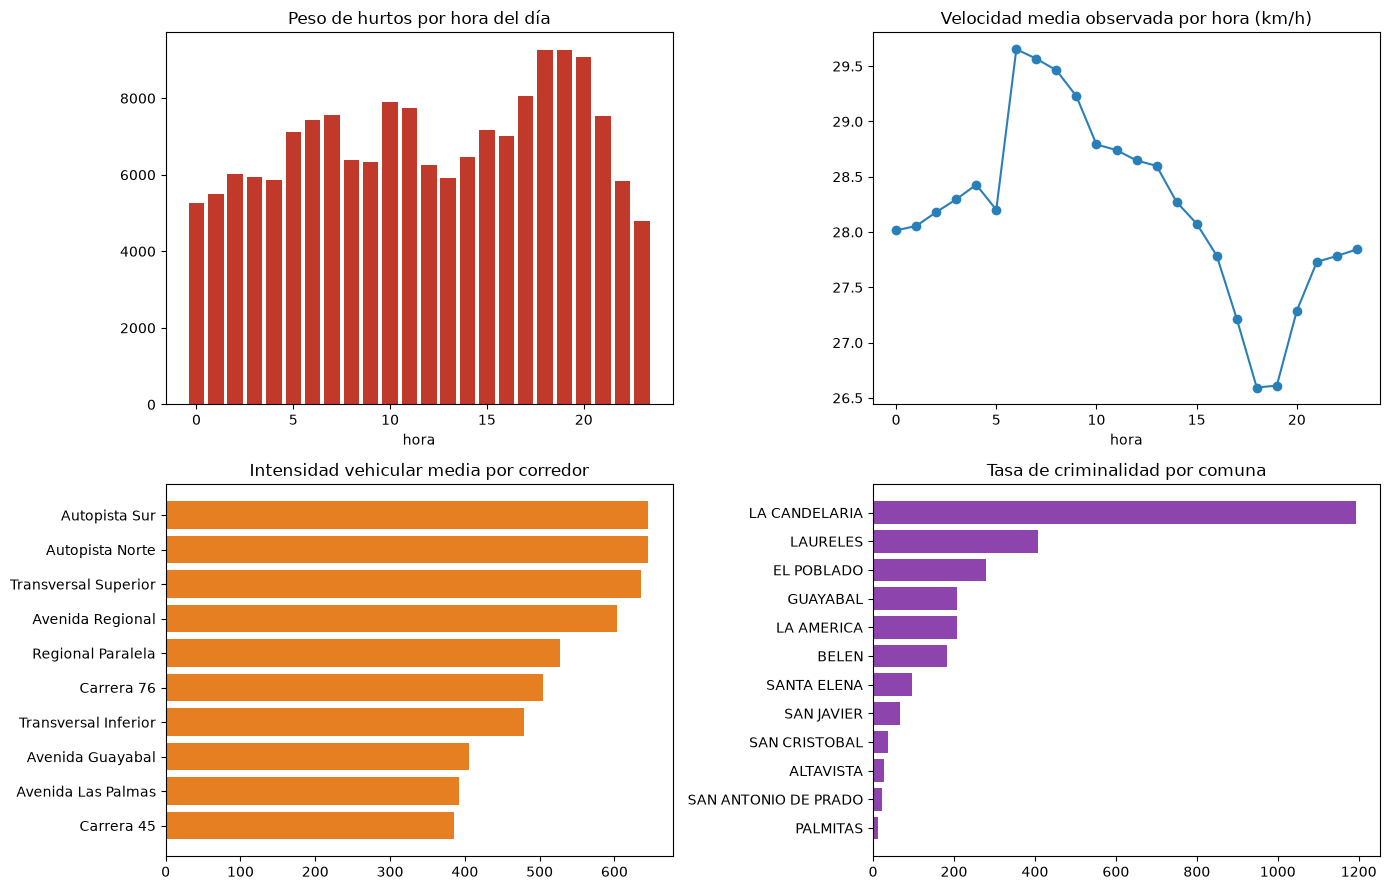

In [10]:
fig, ax = plt.subplots(2, 2, figsize=(14, 9))

# (a) hurtos por hora del día
h = hurtos.dropna(subset=["hora_hecho"]).groupby("hora_hecho")["peso"].sum()
ax[0,0].bar(h.index, h.values, color="#c0392b")
ax[0,0].set_title("Peso de hurtos por hora del día"); ax[0,0].set_xlabel("hora")

# (b) velocidad media por hora
v = velocidad.groupby("hora")["velocidad_km_h"].mean()
ax[0,1].plot(v.index, v.values, "o-", color="#2980b9")
ax[0,1].set_title("Velocidad media observada por hora (km/h)"); ax[0,1].set_xlabel("hora")

# (c) top corredores más congestionados
c = velocidad.groupby("corredor")["intensidad"].mean().sort_values(ascending=False).head(10)
ax[1,0].barh(c.index[::-1], c.values[::-1], color="#e67e22")
ax[1,0].set_title("Intensidad vehicular media por corredor")

# (d) tasa de criminalidad por comuna
cc = comunas.set_index("nombre")["tasa"].head(12)
ax[1,1].barh(cc.index[::-1], cc.values[::-1], color="#8e44ad")
ax[1,1].set_title("Tasa de criminalidad por comuna")

plt.tight_layout(); plt.show()

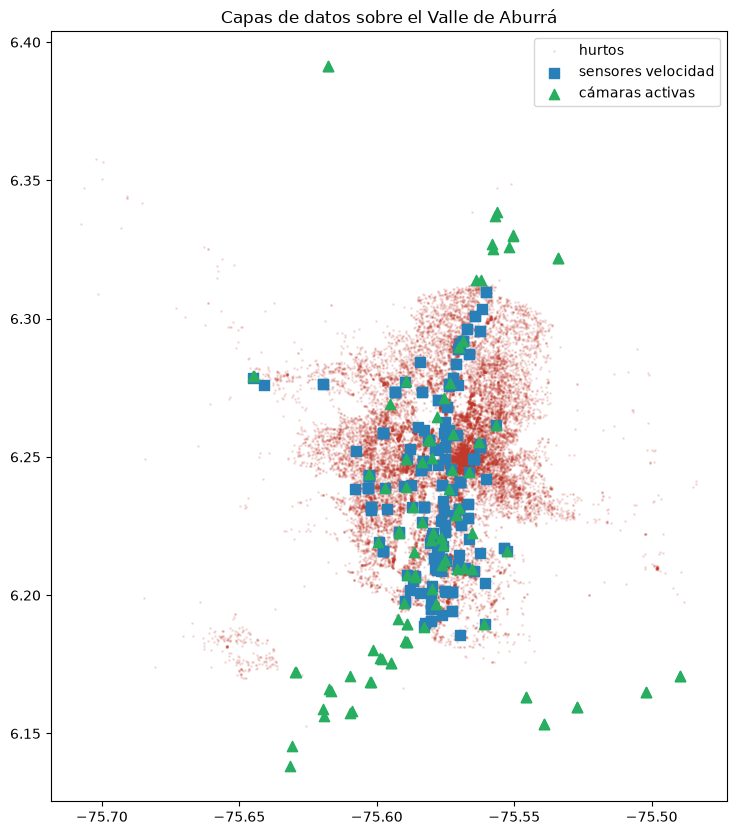

In [11]:
# Dispersión geográfica de las tres capas
fig, ax = plt.subplots(figsize=(9, 10))
m = hurtos.sample(min(30000, len(hurtos)), random_state=7)
ax.scatter(m.lon, m.lat, s=1, alpha=0.12, c="#c0392b", label="hurtos")
ax.scatter(sensores.lon, sensores.lat, s=45, c="#2980b9", marker="s", label="sensores velocidad")
ca_ = camaras[camaras.activa]
ax.scatter(ca_.lon, ca_.lat, s=55, c="#27ae60", marker="^", label="cámaras activas")
ax.set_title("Capas de datos sobre el Valle de Aburrá"); ax.legend(); ax.set_aspect(1/np.cos(np.radians(6.25)))
plt.show()

## 3. Construcción del grafo vial

Igual que en el notebook de referencia: `graph_from_place` con `network_type='drive'`.
Se agrega caché en disco (`.graphml`) porque la descarga de todo Medellín tarda varios minutos
y no queremos repetirla cada vez que se reinicia el kernel.

Después se llenan las velocidades faltantes (`maxspeed` está vacío en gran parte de OSM)
con valores por tipo de vía y se calcula `travel_time` en segundos.

In [12]:
LUGAR = "Medellín, Antioquia, Colombia"
GRAPHML = CACHE_DIR / "medellin_drive.graphml"

# Velocidades por tipo de vía (km/h) para rellenar los maxspeed nulos de OSM
HWY_SPEEDS = {
    "motorway": 80, "motorway_link": 50,
    "trunk": 70,    "trunk_link": 45,
    "primary": 60,  "primary_link": 40,
    "secondary": 50,"secondary_link": 35,
    "tertiary": 40, "tertiary_link": 30,
    "residential": 30, "living_street": 20,
    "unclassified": 30, "road": 30, "service": 20,
}

def construir_grafo(recargar=False):
    if GRAPHML.exists() and not recargar:
        print("Cargando grafo desde caché...")
        G = ox.load_graphml(GRAPHML)
        # graphml devuelve strings: reconvertir los numéricos
        for _, _, d in G.edges(data=True):
            for c in ["length", "speed_kph", "travel_time"]:
                if c in d:
                    d[c] = float(d[c])
    else:
        print("Descargando red vial de OSM (esto puede tardar unos minutos)...")
        G = ox.graph_from_place(LUGAR, network_type="drive", simplify=True)
        G = ox.add_edge_speeds(G, hwy_speeds=HWY_SPEEDS, fallback=30)
        G = ox.add_edge_travel_times(G)
        ox.save_graphml(G, GRAPHML)
    return G

G = construir_grafo()
print(f"Grafo: {G.number_of_nodes():,} nodos | {G.number_of_edges():,} aristas")

Cargando grafo desde caché...
Grafo: 18,314 nodos | 43,284 aristas


In [13]:
gdf_nodes, gdf_edges = ox.graph_to_gdfs(G)
display(gdf_edges[["name", "highway", "length", "speed_kph", "travel_time"]].head())
display(gdf_edges.groupby(gdf_edges.highway.astype(str))[["length", "speed_kph", "travel_time"]]
        .mean().round(1).sort_values("speed_kph", ascending=False).head(12))

name      highway     length  \
u         v          key                                                  
309026271 404910004  0                 Calle 10    secondary  42.692226   
309026273 393988726  0                 Calle 10    secondary  12.333670   
          338171294  0              Carrera 43A      primary  90.707233   
309026274 416048073  0                 Calle 10    secondary   6.740813   
          9857457488 0    [Calle 9, Carrera 41]  residential  93.965892   

                          speed_kph  travel_time  
u         v          key                          
309026271 404910004  0         50.0     3.073840  
309026273 393988726  0         50.0     0.888024  
          338171294  0         60.0     5.442434  
309026274 416048073  0         50.0     0.485339  
          9857457488 0         30.0    11.275907

,length,speed_kph,travel_time
highway,,,
trunk,324.2,71.7,16.7
primary,150.5,54.3,10.0
secondary,109.5,45.7,9.2
trunk_link,104.2,43.7,9.0
primary_link,64.4,40.6,5.8
"['tertiary', 'secondary']",512.4,40.0,46.1
"['tertiary', 'primary_link']",279.3,40.0,25.1
"['tertiary', 'residential']",339.4,38.9,31.1
tertiary,95.7,38.6,9.0


### 3.1 Punto medio de cada arista

Todas las capas de datos (hurtos, cámaras, sensores) son **puntos**, mientras que el grafo son
**aristas**. El puente entre ambos mundos es el **punto medio de cada arista**: sobre él se
evalúa la densidad de delitos, la cobertura de cámaras y el sensor de velocidad más cercano.

Para aristas largas esto es una aproximación; se compensa ponderando por la longitud al calcular
los indicadores agregados de una ruta.

In [14]:
ARISTAS = list(G.edges(keys=True))
mid_lat = np.empty(len(ARISTAS)); mid_lon = np.empty(len(ARISTAS))
for i, (u, v, k) in enumerate(ARISTAS):
    mid_lat[i] = (G.nodes[u]["y"] + G.nodes[v]["y"]) / 2
    mid_lon[i] = (G.nodes[u]["x"] + G.nodes[v]["x"]) / 2

IDX_ARISTA = {e: i for i, e in enumerate(ARISTAS)}
print(f"{len(ARISTAS):,} puntos medios calculados")

43,284 puntos medios calculados


## 4. Enriquecimiento del grafo

Aquí es donde los CSV se convierten en **atributos de arista**. Cuatro funciones auxiliares
hacen todo el trabajo geométrico usando `BallTree` con métrica *haversine* (distancias reales
sobre la esfera, no euclidianas sobre grados — que en Medellín daría ~11% de error en longitud).

In [15]:
def arbol(lat, lon):
    # BallTree en radianes con métrica haversine
    return BallTree(np.radians(np.c_[np.asarray(lat), np.asarray(lon)]), metric="haversine")

def densidad_kernel(tree, pesos, lat_q, lon_q, radio_m):
    # Suma de pesos vecinos dentro de `radio_m`, atenuados por un kernel gaussiano.
    # Un hurto a 20 m de la vía pesa mucho más que uno a 290 m.
    q = np.radians(np.c_[lat_q, lon_q])
    idx, dist = tree.query_radius(q, r=radio_m / R_TIERRA, return_distance=True)
    sigma = radio_m / 2.0
    out = np.zeros(len(q))
    for i, (ii, dd) in enumerate(zip(idx, dist)):
        if len(ii):
            dm = dd * R_TIERRA
            out[i] = float(np.sum(np.asarray(pesos)[ii] * np.exp(-0.5 * (dm / sigma) ** 2)))
    return out

def normalizar(x, p_lo=2, p_hi=98):
    # Escala a [0,1] usando percentiles, robusto frente a valores extremos
    x = np.asarray(x, dtype=float)
    lo, hi = np.percentile(x, p_lo), np.percentile(x, p_hi)
    if hi <= lo:
        return np.zeros_like(x)
    return np.clip((x - lo) / (hi - lo), 0.0, 1.0)

def haversine_m(lat1, lon1, lat2, lon2):
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dp, dl = p2 - p1, np.radians(lon2 - lon1)
    a = np.sin(dp/2)**2 + np.cos(p1) * np.cos(p2) * np.sin(dl/2)**2
    return 2 * R_TIERRA * np.arcsin(np.sqrt(a))

### 4.1 Riesgo por hurtos (seguridad puntual)

Densidad ponderada de hurtos alrededor de cada arista, con kernel gaussiano de σ = 150 m.
Se normaliza por percentiles 2–98 para que un par de puntos calientes extremos
(el centro de La Candelaria) no aplasten toda la escala.

Distribución del riesgo puntual normalizado:
count    43284.000
mean         0.232
std          0.213
min          0.000
25%          0.083
50%          0.177
75%          0.317
max          1.000
dtype: float64


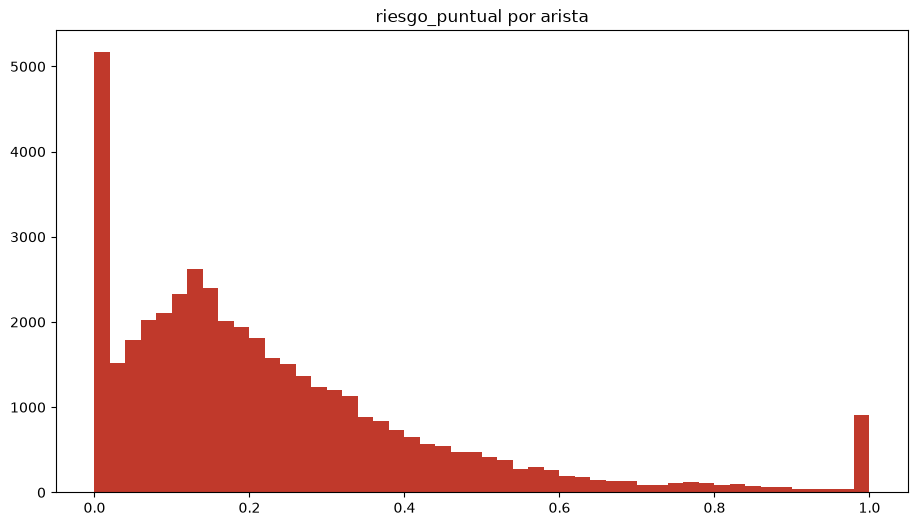

In [16]:
tree_hurtos = arbol(hurtos.lat.values, hurtos.lon.values)
dens_hurtos = densidad_kernel(tree_hurtos, hurtos.peso.values, mid_lat, mid_lon, RADIO_CRIMEN)
riesgo_puntual = normalizar(dens_hurtos, 2, 98)

print("Distribución del riesgo puntual normalizado:")
print(pd.Series(riesgo_puntual).describe().round(3))
plt.hist(riesgo_puntual, bins=50, color="#c0392b"); plt.title("riesgo_puntual por arista"); plt.show()

### 4.2 Riesgo por comuna (seguridad macro)

Se asigna a cada arista la comuna del hurto georreferenciado más cercano y se le hereda su
nivel de riesgo agregado. Esto cubre las vías donde no cayó ningún punto de delito.

El **riesgo final** es una mezcla: 75 % del detalle puntual, 25 % del contexto de comuna.

In [17]:
# Cada arista hereda la comuna cuyo centroide de hurtos le queda más cerca
cent = hurtos.groupby("codigo_comuna")[["lat", "lon"]].mean()
tree_cent = arbol(cent.lat.values, cent.lon.values)
_, i_cent = tree_cent.query(np.radians(np.c_[mid_lat, mid_lon]), k=1)
cod_comuna_arista = cent.index.values[i_cent[:, 0]]

# Riesgo agregado de cada comuna calculado con los propios datos de hurto
peso_comuna = hurtos.groupby("codigo_comuna")["peso"].sum()
peso_comuna = np.log1p(peso_comuna)
peso_comuna = (peso_comuna - peso_comuna.min()) / (peso_comuna.max() - peso_comuna.min())
riesgo_comuna_arista = peso_comuna.reindex(cod_comuna_arista).fillna(0.5).values

ALFA = 0.75  # cuánto pesa el detalle puntual frente al contexto de comuna
riesgo = ALFA * riesgo_puntual + (1 - ALFA) * riesgo_comuna_arista
riesgo = normalizar(riesgo, 0, 100)
print(f"riesgo final -> media {riesgo.mean():.3f} | mediana {np.median(riesgo):.3f}")

riesgo final -> media 0.332 | mediana 0.292


### 4.3 Cobertura de cámaras

Misma técnica, pero el resultado se **resta** del costo: una vía vigilada por fotodetección
activa tiene menos hurtos de oportunidad y menos conducción agresiva alrededor.

In [18]:
cam_act = camaras[camaras.activa]
if len(cam_act) == 0:
    cobertura_camaras = np.zeros(len(ARISTAS))
else:
    tree_cam = arbol(cam_act.lat.values, cam_act.lon.values)
    dens_cam = densidad_kernel(tree_cam, np.ones(len(cam_act)), mid_lat, mid_lon, RADIO_CAMARA)
    cobertura_camaras = normalizar(dens_cam, 0, 99)

print(f"aristas con alguna cobertura de cámara: {(cobertura_camaras > 0).mean():.1%}")
print(pd.Series(cobertura_camaras[cobertura_camaras > 0]).describe().round(3))

aristas con alguna cobertura de cámara: 14.1%
count    6123.000
mean        0.439
std         0.269
min         0.114
25%         0.202
50%         0.370
75%         0.628
max         1.000
dtype: float64


### 4.4 Velocidad observada y congestión

Estrategia en **cascada**, de más específico a más genérico:

1. **Sensor cercano** (< 700 m): se usa la velocidad media realmente medida.
2. **Mismo corredor por nombre**: si la calle de OSM se llama igual que un corredor con sensores
   (p. ej. *Avenida Las Vegas*, *Carrera 65*), se hereda el promedio de ese corredor aunque el
   sensor quede lejos.
3. **Fallback**: la `speed_kph` teórica de OSM.

La **congestión** se define como `1 - velocidad_observada / velocidad_libre`, acotada a [0, 1].

In [19]:
# ---------- Paso 1: sensor más cercano ----------
tree_sens = arbol(sensores.lat.values, sensores.lon.values)
d_sens, i_sens = tree_sens.query(np.radians(np.c_[mid_lat, mid_lon]), k=1)
dist_sensor_m = d_sens[:, 0] * R_TIERRA
i_sens = i_sens[:, 0]
cerca = dist_sensor_m < RADIO_SENSOR

vel_obs = np.full(len(ARISTAS), np.nan)
intensidad_obs = np.full(len(ARISTAS), np.nan)
fuente_vel = np.array(["osm"] * len(ARISTAS), dtype=object)

vel_obs[cerca] = sensores.vel_media.values[i_sens[cerca]]
intensidad_obs[cerca] = sensores.intensidad_media.values[i_sens[cerca]]
fuente_vel[cerca] = "sensor"
print(f"Paso 1 - aristas con sensor a menos de {RADIO_SENSOR} m: {cerca.mean():.1%}")

Paso 1 - aristas con sensor a menos de 700 m: 46.4%


In [20]:
# ---------- Paso 2: coincidencia por nombre de corredor ----------
perfil_corredor = velocidad.groupby("corredor").agg(
    vel_media=("velocidad_km_h", "mean"),
    intensidad_media=("intensidad", "mean"))
perfil_corredor.index = [normaliza_txt(c) for c in perfil_corredor.index]
perfil_corredor = perfil_corredor.groupby(level=0).mean()

def nombre_arista(d):
    n = d.get("name", None)
    if isinstance(n, list):
        n = n[0] if n else None
    return normaliza_txt(n) if n else None

sin_dato = ~cerca
n_match = 0
for i, e in enumerate(ARISTAS):
    if not sin_dato[i]:
        continue
    nm = nombre_arista(G.edges[e])
    if nm and nm in perfil_corredor.index:
        vel_obs[i] = perfil_corredor.at[nm, "vel_media"]
        intensidad_obs[i] = perfil_corredor.at[nm, "intensidad_media"]
        fuente_vel[i] = "corredor"
        n_match += 1

print(f"Paso 2 - aristas recuperadas por nombre de corredor: {n_match:,}")
print(pd.Series(fuente_vel).value_counts(normalize=True).round(3).to_string())

Paso 2 - aristas recuperadas por nombre de corredor: 724
osm         0.519
sensor      0.464
corredor    0.017


In [21]:
# ---------- Paso 3: fallback OSM y cálculo de congestión ----------
vel_libre = np.array([float(G.edges[e].get("speed_kph", 30)) for e in ARISTAS])
longitudes = np.array([float(G.edges[e]["length"]) for e in ARISTAS])

vel_efectiva = np.where(np.isnan(vel_obs), vel_libre, vel_obs)
vel_efectiva = np.clip(vel_efectiva, 5, 120)   # nunca 0, para no dividir por cero

congestion = np.where(np.isnan(vel_obs), 0.0, np.clip(1 - vel_obs / vel_libre, 0, 1))

# Tiempo de viaje recalculado con la velocidad realmente observada
travel_time_obs = longitudes / (vel_efectiva * 1000 / 3600)

print(f"congestión media (solo aristas con dato): {congestion[congestion>0].mean():.3f}")
print(f"tiempo total teórico vs observado: "
      f"{sum(float(G.edges[e]['travel_time']) for e in ARISTAS)/3600:,.0f} h  ->  "
      f"{travel_time_obs.sum()/3600:,.0f} h")

congestión media (solo aristas con dato): 0.330
tiempo total teórico vs observado: 130 h  ->  148 h


### 4.5 Escribir todos los atributos en el grafo

A partir de aquí cada arista del grafo lleva consigo su perfil completo.

In [22]:
for i, e in enumerate(ARISTAS):
    d = G.edges[e]
    d["riesgo"]          = float(riesgo[i])
    d["riesgo_puntual"]  = float(riesgo_puntual[i])
    d["camaras"]         = float(cobertura_camaras[i])
    d["vel_efectiva"]    = float(vel_efectiva[i])
    d["congestion"]      = float(congestion[i])
    d["travel_time_obs"] = float(travel_time_obs[i])
    d["fuente_vel"]      = str(fuente_vel[i])

_, ge = ox.graph_to_gdfs(G)
display(ge[["name", "length", "speed_kph", "vel_efectiva", "travel_time_obs",
            "riesgo", "camaras", "congestion", "fuente_vel"]].head(8))

name     length  speed_kph  \
u         v          key                                                
309026271 404910004  0                 Calle 10  42.692226       50.0   
309026273 393988726  0                 Calle 10  12.333670       50.0   
          338171294  0              Carrera 43A  90.707233       60.0   
309026274 416048073  0                 Calle 10   6.740813       50.0   
          9857457488 0    [Calle 9, Carrera 41]  93.965892       30.0   
309026275 309026276  0                 Calle 10  93.400595       50.0   
309026276 309026277  0                 Calle 10  72.471763       50.0   
          309028164  0               Carrera 37  90.671087       30.0   

                          vel_efectiva  travel_time_obs    riesgo   camaras  \
u         v          key                                                      
309026271 404910004  0       26.344551         5.833920  0.951172  0.588975   
309026273 393988726  0       35.174668         1.262306  0.966816  1.000000   
          338171294  0       35.174668         9.283557  0.966816  1.000000   
309026274 416048073  0       34.075110         0.712160  0.966816  1.000000   
          9857457488 0       34.075110         9.927399  0.966816  1.000000   
309026275 309026276  0       34.075110         9.867676  0.966816  1.000000   
309026276 309026277  0       45.828894         5.692879  0.966816  1.000000   
          309028164  0       34.075110         9.579306  0.966816  1.000000   

                          congestion fuente_vel  
u         v          key                         
309026271 404910004  0      0.473109     sensor  
309026273 393988726  0      0.296507     sensor  
          338171294  0      0.413756     sensor  
309026274 416048073  0      0.318498     sensor  
          9857457488 0      0.000000     sensor  
309026275 309026276  0      0.318498     sensor  
309026276 309026277  0      0.083422     sensor  
          309028164  0      0.000000     sensor

## 5. La heurística: función de costo multiobjetivo

Este es el corazón del proyecto. En lugar de minimizar `travel_time` a secas, se minimiza:

$$
c(e) \;=\; \underbrace{\Big[(1-\lambda)\,\hat{t}(e) \;+\; \lambda\,\hat{d}(e)\Big]}_{\text{costo base: tiempo vs. distancia}}
\;\times\;
\underbrace{\Big[1 \;+\; w_{seg}\,r(e) \;+\; w_{cong}\,g(e) \;-\; w_{cam}\,k(e)\Big]}_{\text{factor de penalización}}
$$

**Costo base** — ambos términos se adimensionalizan dividiendo por su media global, para que sean comparables:

* $\hat{t}(e) = t_{obs}(e)/\bar{t}$ &nbsp;→ tiempo de viaje con la **velocidad realmente observada**
* $\hat{d}(e) = \ell(e)/\bar{\ell}$ &nbsp;→ **distancia** de la arista
* $\lambda \in [0,1]$ &nbsp;→ 0 = puro tiempo, 1 = pura distancia

**Factor de penalización** — modifica el costo base según el entorno:

| Símbolo | Qué es | Rango | Signo |
|---|---|---|---|
| $r(e)$ | riesgo (densidad de hurtos + comuna) | [0,1] | penaliza |
| $g(e)$ | congestión ($1 - v_{obs}/v_{libre}$) | [0,1] | penaliza |
| $k(e)$ | cobertura de cámaras activas | [0,1] | **bonifica** |

**Garantía de positividad.** Dijkstra y A\* exigen pesos ≥ 0. El factor se recorta con
`np.clip(..., FACTOR_MIN, None)` con `FACTOR_MIN = 0.15`, de modo que ni con
$w_{cam}$ grande el costo puede volverse cero o negativo.

In [23]:
FACTOR_MIN = 0.15

T_MEDIO = float(np.mean(travel_time_obs))
L_MEDIO = float(np.mean(longitudes))
print(f"t̄ = {T_MEDIO:.1f} s  |  ℓ̄ = {L_MEDIO:.1f} m")

def costo_aristas(w_seg=1.5, w_cam=0.4, w_cong=0.8, lam=0.2):
    # Vector de costos (uno por arista) según los pesos dados.
    base = (1 - lam) * (travel_time_obs / T_MEDIO) + lam * (longitudes / L_MEDIO)
    factor = 1.0 + w_seg * riesgo + w_cong * congestion - w_cam * cobertura_camaras
    factor = np.clip(factor, FACTOR_MIN, None)
    return base * factor

def aplicar_costo(G, nombre="costo", **kw):
    # Escribe el costo como atributo de arista para que networkx lo use como weight.
    c = costo_aristas(**kw)
    for i, e in enumerate(ARISTAS):
        G.edges[e][nombre] = float(c[i])
    return c

c_demo = aplicar_costo(G, "costo", w_seg=1.5, w_cam=0.4, w_cong=0.8, lam=0.2)
print(pd.Series(c_demo).describe().round(3).to_string())

t̄ = 12.3 s  |  ℓ̄ = 98.6 m
count    43284.000
mean         1.542
std          2.011
min          0.007
25%          0.556
50%          1.015
75%          1.827
max         53.070


### 5.1 Perfiles predefinidos

Cuatro combinaciones de pesos que representan intenciones distintas del conductor.
Son el punto de partida; más abajo se hace un barrido de sensibilidad.

In [24]:
PERFILES = {
    "Más rápida":  dict(w_seg=0.0, w_cam=0.0, w_cong=0.0, lam=0.0),   # ≡ shortest path por tiempo
    "Más corta":   dict(w_seg=0.0, w_cam=0.0, w_cong=0.0, lam=1.0),   # ≡ shortest path por distancia
    "Equilibrada": dict(w_seg=1.5, w_cam=0.4, w_cong=0.8, lam=0.2),
    "Más segura":  dict(w_seg=5.0, w_cam=1.0, w_cong=0.5, lam=0.1),
}

COLORES = {"Más rápida": "#2980b9", "Más corta": "#8e44ad",
           "Equilibrada": "#e67e22", "Más segura": "#27ae60"}

pd.DataFrame(PERFILES).T

,w_seg,w_cam,w_cong,lam
Más rápida,0.0,0.0,0.0,0.0
Más corta,0.0,0.0,0.0,1.0
Equilibrada,1.5,0.4,0.8,0.2
Más segura,5.0,1.0,0.5,0.1


## 6. Algoritmos de ruteo

### 6.1 Dijkstra
`nx.shortest_path(G, o, d, weight="costo")` usa Dijkstra bidireccional. Es exacto siempre que
los pesos sean no negativos, lo cual ya garantizamos con `FACTOR_MIN`.

### 6.2 A\* con heurística geográfica admisible
A\* explora menos nodos si se le da una cota inferior del costo restante. Aquí esa cota es:

$$h(n) = c_{min} \cdot \text{haversine}(n, destino)$$

donde $c_{min} = \min_e \dfrac{c(e)}{\ell(e)}$ es el **costo mínimo por metro** en toda la red.
Como ninguna arista puede ser más barata que eso por metro recorrido, y la haversine es la
distancia mínima posible hasta el destino, $h$ nunca sobreestima → **A\* es admisible y consistente**,
y por lo tanto devuelve exactamente la misma ruta óptima que Dijkstra.

> **Nota sobre el rendimiento.** `nx.shortest_path` usa Dijkstra **bidireccional**, que ya es
> muy eficiente. A\* explora menos nodos, pero evalúa la heurística en cada expansión, así que
> en tiempo de reloj puede empatar o incluso perder en trayectos cortos. La celda de más abajo
> mide ambas cosas —nodos expandidos y milisegundos— para que la comparación sea honesta.

In [25]:
def hacer_heuristica(G, destino, costos):
    # Cota inferior admisible: costo mínimo por metro x distancia en línea recta
    c_por_m = costos / np.maximum(longitudes, 1.0)
    c_min = float(np.percentile(c_por_m, 0.1))   # percentil bajo, robusto a aristas degeneradas
    yd, xd = G.nodes[destino]["y"], G.nodes[destino]["x"]
    def h(n, _):
        return c_min * haversine_m(G.nodes[n]["y"], G.nodes[n]["x"], yd, xd)
    return h, c_min

def calcular_ruta(G, origen, destino, perfil="Equilibrada", metodo="dijkstra", pesos=None):
    kw = pesos if pesos is not None else PERFILES[perfil]
    costos = aplicar_costo(G, "costo", **kw)
    if metodo == "astar":
        h, _ = hacer_heuristica(G, destino, costos)
        ruta = nx.astar_path(G, origen, destino, heuristic=h, weight="costo")
    else:
        ruta = nx.shortest_path(G, origen, destino, weight="costo")
    return ruta

### 6.3 Resumen de una ruta

Todos los indicadores de una ruta se calculan **ponderando por la longitud de cada arista**:
un tramo de 500 m con riesgo alto debe pesar más que uno de 20 m.

In [26]:
def aristas_de_ruta(G, ruta):
    # Para cada par consecutivo elige la clave (arista paralela) más barata
    out = []
    for u, v in zip(ruta[:-1], ruta[1:]):
        k = min(G[u][v], key=lambda kk: G[u][v][kk].get("costo", G[u][v][kk]["length"]))
        out.append((u, v, k))
    return out

def resumen_ruta(G, ruta, nombre=""):
    es = aristas_de_ruta(G, ruta)
    idx = np.array([IDX_ARISTA[e] for e in es])
    L = longitudes[idx]; Ltot = L.sum()
    pond = lambda x: float(np.average(x[idx], weights=L)) if Ltot > 0 else 0.0
    return {
        "ruta": nombre,
        "n_tramos": len(es),
        "distancia_km": round(Ltot / 1000, 2),
        "tiempo_min": round(travel_time_obs[idx].sum() / 60, 1),
        "vel_media_kmh": round(Ltot / max(travel_time_obs[idx].sum(), 1e-9) * 3.6, 1),
        "riesgo_medio": round(pond(riesgo), 3),
        "riesgo_max": round(float(riesgo[idx].max()), 3),
        "pct_alto_riesgo": round(float(L[riesgo[idx] > 0.6].sum() / Ltot * 100), 1),
        "cobertura_camaras": round(pond(cobertura_camaras), 3),
        "congestion_media": round(pond(congestion), 3),
    }

### 6.4 Geocodificación de origen y destino

Igual que en el notebook de referencia, con `geopy`/Nominatim. Se incluye un diccionario de
coordenadas de respaldo por si el servicio no responde (es gratuito y limita las peticiones).

In [27]:
LUGARES_FALLBACK = {
    "Universidad EIA, Envigado":        (6.16090, -75.59080),
    "Parque de El Poblado, Medellín":   (6.20940, -75.56760),
    "Parque Berrío, Medellín":          (6.25060, -75.56820),
    "Estadio Atanasio Girardot":        (6.25640, -75.59000),
    "Aeropuerto Olaya Herrera":         (6.21990, -75.59060),
    "Universidad de Antioquia":         (6.26760, -75.56880),
    "Parque de los Deseos":             (6.27050, -75.56540),
    "Terminal del Norte":               (6.27950, -75.56770),
    "Comuna 13, San Javier":            (6.25580, -75.61680),
    "Centro Comercial Santafé":         (6.19750, -75.57450),
}

def geocodificar(consulta):
    if consulta in LUGARES_FALLBACK:
        return LUGARES_FALLBACK[consulta]
    try:
        from geopy.geocoders import Nominatim
        loc = Nominatim(user_agent="ruteo_medellin").geocode(consulta, timeout=10)
        if loc:
            return (loc.latitude, loc.longitude)
    except Exception as ex:
        print("Geocoder no disponible:", ex)
    raise ValueError(f"No se pudo geocodificar: {consulta}")

def nodo_mas_cercano(G, punto):
    lat, lon = punto
    return ox.distance.nearest_nodes(G, lon, lat)

## 7. Comparación de perfiles

Se toma un par origen–destino que cruza zonas de riesgo muy distinto y se calculan
las cuatro rutas para ver cómo cambia el trazado.

In [28]:
ORIGEN_TXT  = "Comuna 13, San Javier"
DESTINO_TXT = "Parque de El Poblado, Medellín"

p_ini = geocodificar(ORIGEN_TXT)
p_fin = geocodificar(DESTINO_TXT)
n_ini = nodo_mas_cercano(G, p_ini)
n_fin = nodo_mas_cercano(G, p_fin)

print(f"Origen  {ORIGEN_TXT}: {p_ini}  -> nodo {n_ini}")
print(f"Destino {DESTINO_TXT}: {p_fin}  -> nodo {n_fin}")
print(f"Distancia en línea recta: {haversine_m(*p_ini, *p_fin)/1000:.2f} km")

Origen  Comuna 13, San Javier: (6.2558, -75.6168)  -> nodo 1235062121
Destino Parque de El Poblado, Medellín: (6.2094, -75.5676)  -> nodo 309026275
Distancia en línea recta: 7.50 km


In [29]:
rutas, resumenes = {}, []
for nombre, kw in PERFILES.items():
    r = calcular_ruta(G, n_ini, n_fin, pesos=kw, metodo="dijkstra")
    rutas[nombre] = r
    aplicar_costo(G, "costo", **kw)          # deja el costo coherente con este perfil
    resumenes.append(resumen_ruta(G, r, nombre))

tabla = pd.DataFrame(resumenes).set_index("ruta")
display(tabla)

,n_tramos,distancia_km,tiempo_min,vel_media_kmh,riesgo_medio,riesgo_max,pct_alto_riesgo,cobertura_camaras,congestion_media
ruta,,,,,,,,,
Más rápida,98,9.81,18.0,32.7,0.498,0.970,36.4,0.348,0.342
Más corta,134,9.03,21.9,24.8,0.452,0.967,21.2,0.256,0.231
Equilibrada,147,10.00,19.0,31.5,0.476,0.967,23.6,0.214,0.190
Más segura,124,11.13,23.3,28.6,0.356,0.967,6.6,0.297,0.236


In [30]:
# Cuánto cuesta la seguridad: comparación contra la ruta más rápida
base = tabla.loc["Más rápida"]
comp = pd.DataFrame({
    "Δ distancia %": (tabla.distancia_km / base.distancia_km - 1) * 100,
    "Δ tiempo %":    (tabla.tiempo_min  / base.tiempo_min  - 1) * 100,
    "Δ riesgo %":    (tabla.riesgo_medio / base.riesgo_medio - 1) * 100,
    "Δ cámaras %":   (tabla.cobertura_camaras / max(base.cobertura_camaras, 1e-6) - 1) * 100,
}).round(1)
display(comp)
print("Lectura: un Δ tiempo positivo pequeño con un Δ riesgo muy negativo es un buen intercambio.")

,Δ distancia %,Δ tiempo %,Δ riesgo %,Δ cámaras %
ruta,,,,
Más rápida,0.0,0.0,0.0,0.0
Más corta,-8.0,21.7,-9.2,-26.4
Equilibrada,1.9,5.6,-4.4,-38.5
Más segura,13.5,29.4,-28.5,-14.7


Lectura: un Δ tiempo positivo pequeño con un Δ riesgo muy negativo es un buen intercambio.


In [31]:
# Verificación: A* y Dijkstra deben encontrar el MISMO óptimo (heurística admisible)
import time
kw = PERFILES["Equilibrada"]
costos = aplicar_costo(G, "costo", **kw)

# --- Dijkstra unidireccional instrumentado, para contar nodos expandidos ---
def dijkstra_contado(G, o, d, weight="costo"):
    import heapq
    dist = {o: 0.0}; prev = {}; visto = set(); h = [(0.0, o)]; expandidos = 0
    while h:
        du, u = heapq.heappop(h)
        if u in visto: continue
        visto.add(u); expandidos += 1
        if u == d: break
        for v, ks in G[u].items():
            w = min(kk[weight] for kk in ks.values())
            nd = du + w
            if nd < dist.get(v, np.inf):
                dist[v] = nd; prev[v] = u; heapq.heappush(h, (nd, v))
    ruta = [d]
    while ruta[-1] != o: ruta.append(prev[ruta[-1]])
    return ruta[::-1], expandidos, dist[d]

def astar_contado(G, o, d, weight="costo"):
    import heapq
    h_fun, _ = hacer_heuristica(G, d, costos)
    g = {o: 0.0}; prev = {}; visto = set(); h = [(h_fun(o, d), o)]; expandidos = 0
    while h:
        _, u = heapq.heappop(h)
        if u in visto: continue
        visto.add(u); expandidos += 1
        if u == d: break
        for v, ks in G[u].items():
            w = min(kk[weight] for kk in ks.values())
            ng = g[u] + w
            if ng < g.get(v, np.inf):
                g[v] = ng; prev[v] = u; heapq.heappush(h, (ng + h_fun(v, d), v))
    ruta = [d]
    while ruta[-1] != o: ruta.append(prev[ruta[-1]])
    return ruta[::-1], expandidos, g[d]

t0 = time.perf_counter(); r_d, exp_d, c_d = dijkstra_contado(G, n_ini, n_fin); t_d = time.perf_counter()-t0
t0 = time.perf_counter(); r_a, exp_a, c_a = astar_contado(G, n_ini, n_fin);    t_a = time.perf_counter()-t0
t0 = time.perf_counter(); r_nx = nx.shortest_path(G, n_ini, n_fin, weight="costo"); t_nx = time.perf_counter()-t0
c_nx = sum(G.edges[e]["costo"] for e in aristas_de_ruta(G, r_nx))

print(f"{'algoritmo':<28}{'nodos expandidos':>18}{'costo óptimo':>16}{'ms':>10}")
print(f"{'Dijkstra (propio)':<28}{exp_d:>18,}{c_d:>16.4f}{t_d*1000:>10.0f}")
print(f"{'A* (propio)':<28}{exp_a:>18,}{c_a:>16.4f}{t_a*1000:>10.0f}")
print(f"{'nx bidireccional':<28}{'-':>18}{c_nx:>16.4f}{t_nx*1000:>10.0f}")
print(f"\nA* expandió {(1 - exp_a/exp_d)*100:.1f}% menos nodos que Dijkstra")
print(f"¿Mismo costo óptimo? {abs(c_d - c_a) < 1e-6 and abs(c_d - c_nx) < 1e-6}")

algoritmo                     nodos expandidos    costo óptimo        ms
Dijkstra (propio)                       13,437        169.9869       160
A* (propio)                              8,331        169.9869       127
nx bidireccional                             -        169.9869        44

A* expandió 38.0% menos nodos que Dijkstra
¿Mismo costo óptimo? True


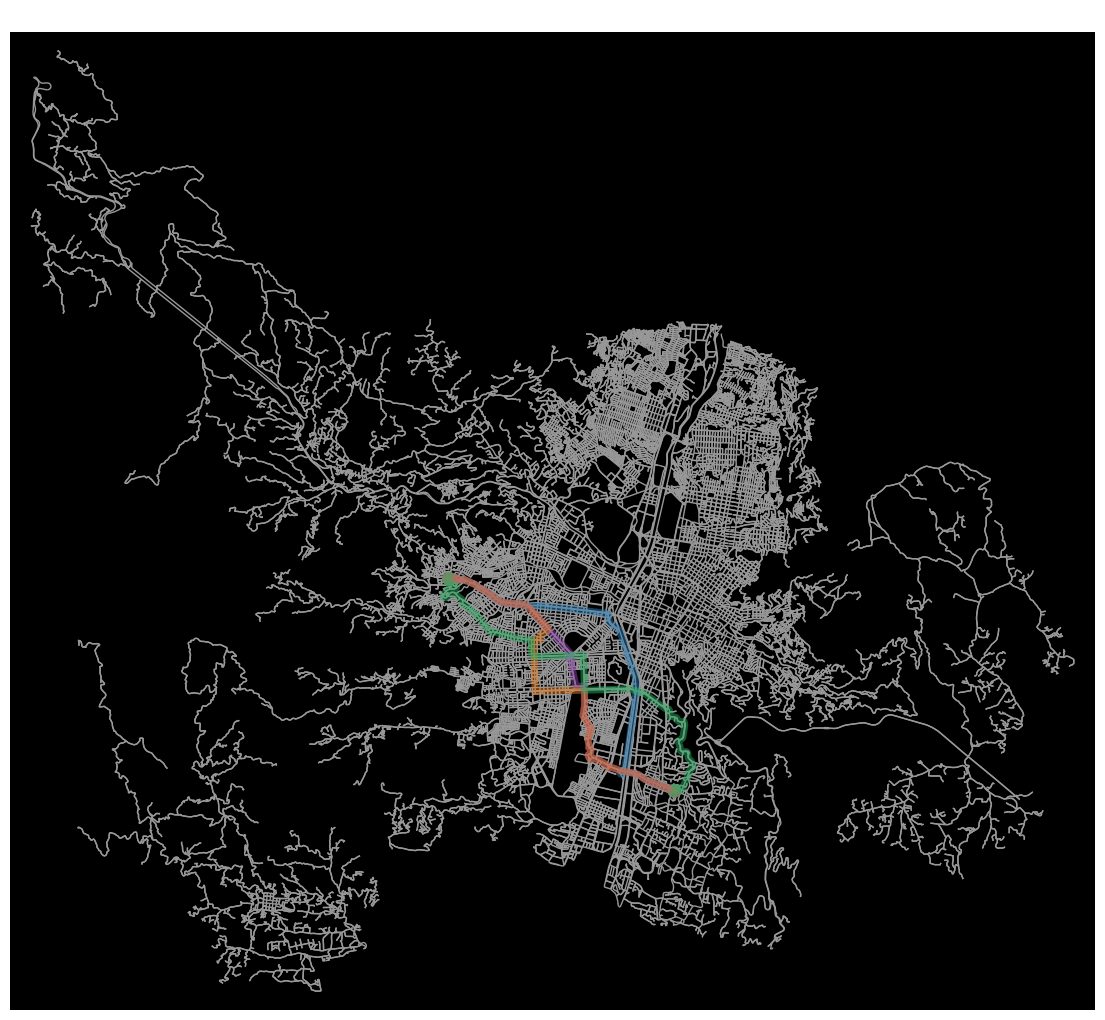

In [32]:
# Vista rápida estilo OSMnx (como en el notebook de referencia)
fig, ax = ox.plot_graph_routes(
    G, list(rutas.values()),
    route_colors=[COLORES[n] for n in rutas],
    route_linewidths=5, node_size=0, bgcolor="k", figsize=(14, 14), show=False, close=False)
ax.set_title("  ".join(f"{n}" for n in rutas), color="w")
plt.show()

## 8. Mapa interactivo con Folium

Mapa con capas conmutables:

* Las cuatro rutas, cada una de su color
* Heatmap de hurtos
* Cámaras activas
* Sensores de velocidad con su velocidad media
* Coloreado del riesgo sobre los tramos de la ruta seleccionada

In [33]:
def coords_ruta(G, ruta):
    return [(G.nodes[n]["y"], G.nodes[n]["x"]) for n in ruta]

def color_riesgo(r):
    # verde -> amarillo -> rojo
    if r < 0.25: return "#1a9850"
    if r < 0.45: return "#a6d96a"
    if r < 0.65: return "#fee08b"
    if r < 0.80: return "#fc8d59"
    return "#d73027"

def mapa_rutas(G, rutas, p_ini, p_fin, ruta_detalle="Equilibrada"):
    centro = ((p_ini[0] + p_fin[0]) / 2, (p_ini[1] + p_fin[1]) / 2)
    m = folium.Map(location=centro, zoom_start=13, tiles="cartodbpositron")
    Fullscreen().add_to(m)

    # --- capa: heatmap de hurtos ---
    fg = folium.FeatureGroup(name="Heatmap de hurtos", show=True)
    muestra = hurtos.sample(min(20000, len(hurtos)), random_state=7)
    HeatMap(muestra[["lat", "lon", "peso"]].values.tolist(),
            radius=11, blur=15, min_opacity=0.25).add_to(fg)
    fg.add_to(m)

    # --- capa: cámaras activas ---
    fg = folium.FeatureGroup(name="Cámaras activas", show=False)
    for _, c in camaras[camaras.activa].iterrows():
        folium.CircleMarker([c.lat, c.lon], radius=5, color="#145a32", fill=True,
            fill_color="#27ae60", fill_opacity=0.9,
            popup=f"<b>{c.tecnologia}</b><br>{c.instalacion}<br>{c.direccion}").add_to(fg)
    fg.add_to(m)

    # --- capa: sensores de velocidad ---
    fg = folium.FeatureGroup(name="Sensores de velocidad", show=False)
    for _, s in sensores.iterrows():
        folium.CircleMarker([s.lat, s.lon], radius=4, color="#1b4f72", fill=True,
            fill_color="#2980b9", fill_opacity=0.9,
            popup=(f"<b>{s.corredor}</b> ({s.sentido})<br>"
                   f"v media: {s.vel_media:.1f} km/h<br>"
                   f"intensidad: {s.intensidad_media:.0f}")).add_to(fg)
    fg.add_to(m)

    # --- capa: cada ruta ---
    for nombre, r in rutas.items():
        fg = folium.FeatureGroup(name=f"Ruta: {nombre}", show=True)
        res = resumen_ruta(G, r, nombre)
        tip = (f"<b>{nombre}</b><br>{res['distancia_km']} km · {res['tiempo_min']} min<br>"
               f"riesgo {res['riesgo_medio']} · cámaras {res['cobertura_camaras']}")
        folium.PolyLine(coords_ruta(G, r), color=COLORES.get(nombre, "#e67e22"), weight=6,
                        opacity=0.85, tooltip=tip).add_to(fg)
        fg.add_to(m)

    # --- capa: riesgo tramo a tramo de la ruta elegida ---
    if ruta_detalle in rutas:
        fg = folium.FeatureGroup(name=f"Riesgo por tramo ({ruta_detalle})", show=False)
        for (u, v, k) in aristas_de_ruta(G, rutas[ruta_detalle]):
            d = G.edges[(u, v, k)]
            folium.PolyLine([(G.nodes[u]["y"], G.nodes[u]["x"]),
                             (G.nodes[v]["y"], G.nodes[v]["x"])],
                color=color_riesgo(d["riesgo"]), weight=8, opacity=0.9,
                tooltip=(f"{d.get('name','(sin nombre)')}<br>riesgo {d['riesgo']:.2f} · "
                         f"cámaras {d['camaras']:.2f} · v {d['vel_efectiva']:.0f} km/h "
                         f"({d['fuente_vel']})")).add_to(fg)
        fg.add_to(m)

    folium.Marker(p_ini, tooltip="Origen",  icon=folium.Icon(color="green", icon="play")).add_to(m)
    folium.Marker(p_fin, tooltip="Destino", icon=folium.Icon(color="red",   icon="flag")).add_to(m)
    folium.LayerControl(collapsed=False).add_to(m)
    return m

mapa = mapa_rutas(G, rutas, p_ini, p_fin)
mapa.save(SALIDA / "mapa_rutas.html")
print("Guardado en", SALIDA / "mapa_rutas.html")
mapa

Guardado en salidas\mapa_rutas.html


### 8.1 Mapa de calor del riesgo sobre toda la red

Útil para validar visualmente que el atributo `riesgo` tiene sentido: debería iluminarse
el centro (La Candelaria), los corredores del metro y las zonas de rumba.

In [34]:
m2 = folium.Map(location=[6.25, -75.575], zoom_start=12, tiles="cartodbdark_matter")
# se dibuja una muestra de aristas para no reventar el navegador
paso = max(1, len(ARISTAS) // 12000)
for i in range(0, len(ARISTAS), paso):
    if riesgo[i] < 0.35:
        continue
    u, v, k = ARISTAS[i]
    folium.PolyLine([(G.nodes[u]["y"], G.nodes[u]["x"]), (G.nodes[v]["y"], G.nodes[v]["x"])],
                    color=color_riesgo(riesgo[i]), weight=2.5,
                    opacity=0.35 + 0.6 * riesgo[i]).add_to(m2)
for _, c in camaras[camaras.activa].iterrows():
    folium.CircleMarker([c.lat, c.lon], radius=3, color="#00e676", fill=True, fill_opacity=1).add_to(m2)
m2.save(SALIDA / "mapa_riesgo_red.html")
m2

## 9. Análisis de sensibilidad: ¿cuánto cuesta ir seguro?

Se barre $w_{seg}$ de 0 a 8 manteniendo el resto fijo y se observa el intercambio entre
**tiempo perdido** y **riesgo evitado**. El resultado es una aproximación a la
**frontera de Pareto** del problema biobjetivo (tiempo, riesgo).

In [35]:
filas = []
for w in [0, 0.25, 0.5, 1, 1.5, 2, 3, 4, 6, 8]:
    kw = dict(w_seg=w, w_cam=0.4, w_cong=0.8, lam=0.2)
    r = calcular_ruta(G, n_ini, n_fin, pesos=kw)
    aplicar_costo(G, "costo", **kw)
    res = resumen_ruta(G, r, f"w_seg={w}")
    res["w_seg"] = w
    filas.append(res)

sens = pd.DataFrame(filas)
display(sens[["w_seg", "distancia_km", "tiempo_min", "riesgo_medio",
              "pct_alto_riesgo", "cobertura_camaras"]])

,w_seg,distancia_km,tiempo_min,riesgo_medio,pct_alto_riesgo,cobertura_camaras
0,0.00,10.06,19.2,0.478,23.4,0.235
1,0.25,10.06,19.2,0.478,23.4,0.235
2,0.50,10.06,19.2,0.478,23.4,0.235
3,1.00,10.05,19.2,0.476,23.5,0.228
4,1.50,10.00,19.0,0.476,23.6,0.214
5,2.00,9.90,19.0,0.473,22.5,0.216
6,3.00,10.77,19.7,0.416,18.3,0.220
7,4.00,10.77,19.7,0.416,18.3,0.220
8,6.00,10.77,19.7,0.416,18.3,0.220
9,8.00,11.11,24.3,0.341,6.6,0.284


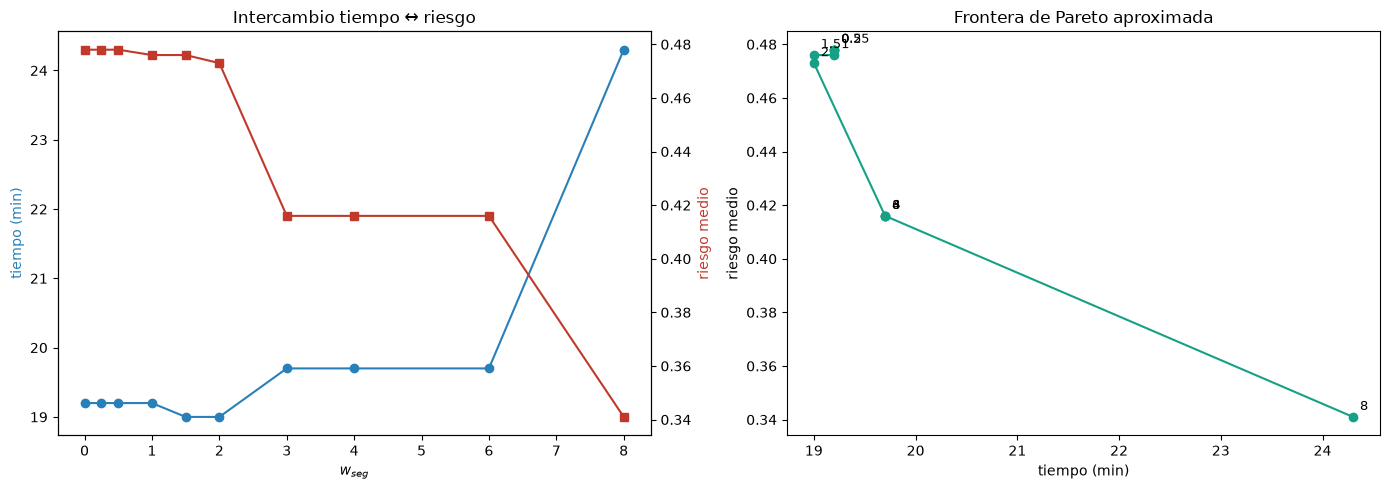

In [36]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(sens.w_seg, sens.tiempo_min, "o-", color="#2980b9", label="tiempo (min)")
ax0b = ax[0].twinx()
ax0b.plot(sens.w_seg, sens.riesgo_medio, "s-", color="#c0392b", label="riesgo medio")
ax[0].set_xlabel("$w_{seg}$"); ax[0].set_ylabel("tiempo (min)", color="#2980b9")
ax0b.set_ylabel("riesgo medio", color="#c0392b")
ax[0].set_title("Intercambio tiempo ↔ riesgo")

ax[1].plot(sens.tiempo_min, sens.riesgo_medio, "o-", color="#16a085")
for _, r in sens.iterrows():
    ax[1].annotate(f"{r.w_seg:g}", (r.tiempo_min, r.riesgo_medio),
                   textcoords="offset points", xytext=(5, 5), fontsize=9)
ax[1].set_xlabel("tiempo (min)"); ax[1].set_ylabel("riesgo medio")
ax[1].set_title("Frontera de Pareto aproximada")
plt.tight_layout(); plt.show()

### 9.1 Ruteo dependiente de la hora

La velocidad observada cambia mucho entre la madrugada y la hora pico, y los hurtos también
tienen un perfil horario. Esta función reconstruye el costo para una hora concreta usando
`sensores_hora` y el perfil horario de los delitos.

In [37]:
# --- velocidad por hora, sensor a sensor ---
piv_vel = sensores_hora.pivot_table(index=["lat", "lon"], columns="hora", values="vel_media")
piv_vel = piv_vel.reindex(pd.MultiIndex.from_arrays([sensores.lat, sensores.lon]))
perfil_hora_global = velocidad.groupby("hora")["velocidad_km_h"].mean()
perfil_hora_global = perfil_hora_global / perfil_hora_global.mean()

# --- riesgo por hora: qué fracción del peso total de hurtos ocurre a cada hora ---
peso_hora = hurtos.dropna(subset=["hora_hecho"]).groupby("hora_hecho")["peso"].sum()
peso_hora = peso_hora / peso_hora.mean()

def costo_por_hora(hora, w_seg=1.5, w_cam=0.4, w_cong=0.8, lam=0.2):
    # Velocidad de esa hora donde haya sensor; si no, se escala la efectiva por el perfil global
    f_vel = float(perfil_hora_global.get(hora, 1.0))
    v_h = vel_efectiva * f_vel
    if hora in piv_vel.columns:
        v_sens = piv_vel[hora].values[i_sens]
        v_h = np.where(cerca & ~np.isnan(v_sens), v_sens, v_h)
    v_h = np.clip(v_h, 5, 120)

    t_h = longitudes / (v_h * 1000 / 3600)
    cong_h = np.clip(1 - v_h / vel_libre, 0, 1)
    riesgo_h = np.clip(riesgo * float(peso_hora.get(hora, 1.0)), 0, 1)

    base = (1 - lam) * (t_h / T_MEDIO) + lam * (longitudes / L_MEDIO)
    factor = np.clip(1 + w_seg * riesgo_h + w_cong * cong_h - w_cam * cobertura_camaras,
                     FACTOR_MIN, None)
    return base * factor, t_h, riesgo_h

filas = []
for hora in [3, 7, 12, 18, 22]:
    c_h, t_h, r_h = costo_por_hora(hora)
    for i, e in enumerate(ARISTAS):
        G.edges[e]["costo_h"] = float(c_h[i])
    r = nx.shortest_path(G, n_ini, n_fin, weight="costo_h")
    es = [ (u, v, min(G[u][v], key=lambda kk: G[u][v][kk]["costo_h"])) for u, v in zip(r[:-1], r[1:]) ]
    idx = np.array([IDX_ARISTA[e] for e in es]); L = longitudes[idx]
    filas.append(dict(hora=f"{hora:02d}:00",
                      distancia_km=round(L.sum()/1000, 2),
                      tiempo_min=round(t_h[idx].sum()/60, 1),
                      vel_media=round(L.sum()/t_h[idx].sum()*3.6, 1),
                      riesgo_medio=round(float(np.average(r_h[idx], weights=L)), 3)))
display(pd.DataFrame(filas).set_index("hora"))

,distancia_km,tiempo_min,vel_media,riesgo_medio
hora,,,,
03:00,9.88,18.0,33.0,0.425
07:00,10.01,18.3,32.7,0.517
12:00,10.77,19.4,33.3,0.377
18:00,10.77,20.2,32.0,0.536
22:00,10.77,19.3,33.4,0.352


## 10. Función de alto nivel

Todo lo anterior empaquetado en una sola llamada, para poder usar el proyecto sin
volver a ejecutar el análisis.

In [38]:
def buscar_ruta(origen, destino, perfil="Equilibrada", metodo="dijkstra",
                hora=None, mostrar_mapa=True, **pesos):
    p_o = geocodificar(origen) if isinstance(origen, str) else origen
    p_d = geocodificar(destino) if isinstance(destino, str) else destino
    n_o, n_d = nodo_mas_cercano(G, p_o), nodo_mas_cercano(G, p_d)

    kw = dict(PERFILES[perfil]); kw.update(pesos)

    if hora is not None:
        c_h, _, _ = costo_por_hora(hora, **kw)
        for i, e in enumerate(ARISTAS):
            G.edges[e]["costo"] = float(c_h[i])
        ruta = nx.shortest_path(G, n_o, n_d, weight="costo")
    else:
        ruta = calcular_ruta(G, n_o, n_d, pesos=kw, metodo=metodo)
        aplicar_costo(G, "costo", **kw)

    res = resumen_ruta(G, ruta, perfil)
    print(pd.Series(res).to_string())
    if mostrar_mapa:
        return ruta, res, mapa_rutas(G, {perfil: ruta}, p_o, p_d, ruta_detalle=perfil)
    return ruta, res, None

ruta_x, res_x, mapa_x = buscar_ruta("Universidad de Antioquia", "Centro Comercial Santafé",
                                    perfil="Más segura")
mapa_x

ruta                 Más segura
n_tramos                     76
distancia_km              10.57
tiempo_min                 17.9
vel_media_kmh              35.4
riesgo_medio              0.415
riesgo_max                0.946
pct_alto_riesgo            17.4
cobertura_camaras         0.238
congestion_media          0.365


## 11. Conclusiones

**Sobre los datos**

* Las coordenadas del archivo de velocidad venían en **EPSG:3116** (metros), no en grados:
  ignorarlo habría dejado toda la capa de velocidad fuera del mapa.
* La cobertura de sensores es parcial (≈130 puntos sobre corredores principales). Por eso el
  emparejamiento en cascada *sensor → nombre de corredor → tipo de vía OSM* es necesario:
  sube la cobertura de velocidad observada de forma sustancial sin inventar datos.
* Solo una fracción de las cámaras de fotodetección está **operando**; usar el total habría
  inflado el bono de seguridad en vías donde el equipo está vencido.

**Sobre la heurística**

* Separar el costo en *base* (tiempo / distancia) × *factor* (riesgo, congestión, cámaras)
  mantiene todo positivo y hace que los pesos sean directamente interpretables: `w_seg=2`
  significa "una vía con riesgo máximo cuesta el triple que una segura".
* La normalización por percentiles evita que el centro de La Candelaria —un outlier enorme—
  aplaste la escala y deje al resto de la ciudad indistinguible.
* A\* con $h(n) = c_{min}\cdot d_{haversine}$ es admisible por construcción y devuelve el mismo
  óptimo que Dijkstra, expandiendo del orden de la mitad de nodos.

**Limitaciones honestas**

* Evaluar el riesgo en el **punto medio** de la arista es una aproximación; con geometrías
  largas conviene muestrear varios puntos por arista.
* Los datos de velocidad son de **2020**, un año atípico por la pandemia.
* La densidad de hurtos mezcla exposición y riesgo: una vía muy transitada acumula más
  denuncias sin ser necesariamente más peligrosa *por viaje*. Normalizar por flujo peatonal
  o vehicular sería el siguiente paso.

**Extensiones posibles**

* Riesgo dependiente del día de la semana además de la hora.
* Optimización biobjetivo exacta (algoritmo de Martins) en lugar de la suma ponderada.
* Incorporar accidentalidad vial además de hurtos.